In [ ]:
!pip install ipywidgets
!pip install jupyterlab_widgets

In [ ]:
import os
import torch

# 1. SETTINGS FOR LOCAL JUPYTER
IS_COLAB = False

# 2. PATHS (Update 'save_dir' to your Google Drive Desktop folder)
# Use 'r' before the string to handle Windows backslashes
base_folder = os.getcwd()
data_path = os.path.join(base_folder, "ham10000_data")

# CHANGE THIS to your actual Google Drive path to enable auto-sync
save_dir = r"C:\Users\Admin\Google Drive\MyDrive\skin_cancer_models"

os.makedirs(data_path, exist_ok=True)
os.makedirs(save_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
print(f"Data Path: {os.path.abspath(data_path)}")
print(f"Save Path (Google Drive): {os.path.abspath(save_dir)}")

Device: cuda
Data Path: D:\vit+llm\ham10000_data
Save Path (Google Drive): C:\Users\Admin\Google Drive\MyDrive\skin_cancer_models


# 1. BASIC SETUP

In [ ]:
import os, gc, torch, numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from copy import deepcopy
import random # Import the random module

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.transforms import RandAugment
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.model_selection import train_test_split
from torch.amp import autocast, GradScaler

# Function to set random seeds for reproducibility
def set_all_seeds(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Set a global seed (e.g., 42, consistent with train_test_split)
set_all_seeds(42)

print("torch: ", torch.__version__)
print("cuda: ", torch.cuda.is_available())
print("\n")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


torch:  2.5.1+cu121
cuda:  True


cuda


In [ ]:
!pip install --upgrade kaggle

In [ ]:
import os
import zipfile
from kaggle.api.kaggle_api_extended import KaggleApi
import json
# 1. Credentials - ensure these are my actual strings
K_USER = "KAGGLE_KEY"
KAGGLE_KEY = "Generated Token Value"

def download_data():
    # 2. CREATING THE FILE LOCALLY
    #Creating json
    kaggle_path = os.path.expanduser("~/.kaggle")
    os.makedirs(kaggle_path, exist_ok=True)

    with open(os.path.join(kaggle_path, "kaggle.json"), "w") as f:
        json.dump({"username": K_USER, "key": KAGGLE_KEY}, f)


    try:
        os.chmod(os.path.join(kaggle_path, "kaggle.json"), 0o600)
    except:
        pass # Windows handles permissions differently, so we skip if it fails

    # 3. AUTHENTICATE AND DOWNLOAD
    api = KaggleApi()
    api.authenticate()
    print("Authentication successful! Dataset downloading...")

    csv_file = os.path.join(data_path, "HAM10000_metadata.csv")

    if not os.path.exists(csv_file):
        # Direct API download call
        api.dataset_download_files('kmader/skin-cancer-mnist-ham10000', path=data_path, unzip=True)
        print("Download and extraction complete!")
    else:
        print("Dataset already exists locally.")

download_data()

Authentication successful! Dataset downloading...
Dataset already exists locally.


In [ ]:
# Run if the folder is empty
if not os.path.exists(os.path.join(data_path, "HAM10000_metadata.csv")):
    import kaggle
    print("Downloading dataset...")
    !kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p "{data_path}" --unzip
else:
    print("Dataset already exists!")

Dataset already exists!


# 2. Paths, Metadata, label map

In [ ]:
image_path1 = os.path.join(data_path, "HAM10000_images_part_1")
image_path2 = os.path.join(data_path, "HAM10000_images_part_2")

os.makedirs(save_dir, exist_ok=True)

def get_image_path(image_id):
    p1 = os.path.join(image_path1, image_id + ".jpg")
    p2 = os.path.join(image_path2, image_id + ".jpg")
    if os.path.exists(p1):
        return p1
    return p2

# 1. Load the metadata
metadata = pd.read_csv(os.path.join(data_path, "HAM10000_metadata.csv"))

# 2. CREATE THE LABEL MAP (This was the missing part!)
# This converts disease codes like 'akiec' into numbers 0-6
label_map = {label: idx for idx, label in enumerate(metadata["dx"].unique())}
metadata["label"] = metadata["dx"].map(label_map)

# 3. Map image paths
metadata["image_path"] = metadata["image_id"].apply(get_image_path)

# 4. Now the split will work because 'label' exists
train_df, temp_df = train_test_split(
    metadata, test_size=0.2, stratify=metadata["label"], random_state=42
)

# Then, split the Temporary set in half to get Val and Test (10/10)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["label"], random_state=42
)


# Using Weighted Random Sampler
def random_sampler(df):
  class_counts = df["label"].value_counts().sort_index().values
  sample_weights = [1.0/class_counts[label] for label in df["label"]]
  return WeightedRandomSampler(
      weights=sample_weights,
      num_samples=len(sample_weights),
      replacement=True
  )

print("Label map: ", label_map)
print(f"Train: {len(train_df)} | Test: {len(test_df)}  | Val={len(val_df)}")
print(f"Check: Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}")

Label map:  {'bkl': 0, 'nv': 1, 'df': 2, 'mel': 3, 'vasc': 4, 'bcc': 5, 'akiec': 6}
Train: 8012 | Test: 1002  | Val=1001
Check: Train=8012 | Val=1001 | Test=1002


# 3. Dataset with per-class augmentation

In [ ]:
minority_classes = {label_map[k] for k in ["df", "vasc", "bcc", "akiec"]}

minority_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=30),
    RandAugment(num_ops=2, magnitude=9),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2)
])

majority_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=15)
])

class HAM10000(Dataset):
  def __init__(self, df, processor, is_train=True):
    self.df = df.reset_index(drop=True)
    self.processor=processor
    self.is_train =is_train

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    row = self.df.iloc[idx]
    try:
      image = Image.open(row["image_path"]).convert("RGB")
    except:
      image = Image.new("RGB", (224, 224), 0)

    if self.is_train:
      if row["label"] in minority_classes:
        image = minority_transform(image)
      else:
        image = majority_transform(image)

    enc = self.processor(images=image, return_tensors="pt")
    return {
        "pixel_values": enc["pixel_values"].squeeze(0),
        "labels": torch.tensor(row["label"], dtype=torch.long)
    }

# 4. Mixup helper

In [ ]:
def mixup_batch(pixel_values, labels, num_classes=7, alpha=0.4):
  """
  Improves ViT generalization by mixing two batches together with a random lambda.
  Softens decision boundaries
  """
  lamb = np.random.beta(alpha, alpha)
  perm = torch.randperm(pixel_values.size(0), device=pixel_values.device)
  mixed_pv = lamb * pixel_values + (1 - lamb) * pixel_values[perm]

  y_a = F.one_hot(labels, num_classes).float()
  y_b = F.one_hot(labels[perm], num_classes).float()
  mixed_y = lamb * y_a + (1 - lamb) * y_b

  return mixed_pv, mixed_y

# 5. Model config

In [ ]:
MODEL_CONFIG = {
    "vit"  : "google/vit-base-patch16-224",
    "swin" : "microsoft/swin-tiny-patch4-window7-224",
    "deit" : "facebook/deit-base-patch16-224",
    "beit" : "microsoft/beit-base-patch16-224",
}

EPOCHS = 30 # Increased epochs for better convergence
BATCH_SIZE = 16
LR = 2e-5

# Dynamically set NUM_WORKERS and PIN_MEMORY based on device
if device.type == "cuda":
    NUM_WORKERS = 0
    PIN_MEMORY = True
else:
    NUM_WORKERS = 0
    PIN_MEMORY = False

PREFETCH=2

# 6. Training function

In [ ]:
def train_one_model(model_key, epochs=EPOCHS):
  # Use single quotes inside the curly braces to avoid SyntaxError
  print(f"\n{'='*60}")
  print(f" Training: {model_key.upper()}")
  print(f"{'='*60}")

  hf_name = MODEL_CONFIG[model_key]
  processor = AutoImageProcessor.from_pretrained(hf_name, use_fast=True)

  train_ds = HAM10000(train_df, processor, is_train=True)
  test_ds  = HAM10000(test_df,  processor, is_train=False)

  # Use weighted sampler for training data
  sampler = random_sampler(train_df)
  # Updated DataLoader for Windows compatibility
  train_loader = DataLoader(
      train_ds,
      batch_size=BATCH_SIZE,
      sampler=sampler,
      num_workers=NUM_WORKERS,
      pin_memory=PIN_MEMORY,
      prefetch_factor=None if NUM_WORKERS == 0 else 2 # FIX: Set to None if workers are 0
  )

  test_loader  = DataLoader(
      test_ds,
      batch_size=BATCH_SIZE,
      shuffle=False,
      num_workers=NUM_WORKERS,
      pin_memory=PIN_MEMORY,
      prefetch_factor=None if NUM_WORKERS == 0 else 2 # FIX: Set to None if workers are 0
  )

  model = AutoModelForImageClassification.from_pretrained(
      hf_name, num_labels=len(label_map), ignore_mismatched_sizes=True,
      use_safetensors=True #<= SPECIALLY FOR RUNNING DEIT & BEIT
  )
  model.to(device)

  optimizer = AdamW(model.parameters(), lr=LR)
  scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
  scaler = GradScaler() if device.type == "cuda" else None

  best_val_acc = 0.0
  best_model_state = None
  best_epoch = -1

  for epoch in range(epochs):
    model.train()
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", dynamic_ncols=True)
    train_loss = 0.0
    for batch in pbar:
      pixel_values, labels = batch["pixel_values"].to(device), batch["labels"].to(device)
      pixel_values, labels = mixup_batch(pixel_values, labels, num_classes=len(label_map))

      optimizer.zero_grad()
      if scaler:
          with autocast(device_type="cuda", dtype=torch.float16):
              outputs = model(pixel_values=pixel_values)
              loss = F.cross_entropy(outputs.logits, labels)
          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()
      else:
          outputs = model(pixel_values=pixel_values)
          loss = F.cross_entropy(outputs.logits, labels)
          loss.backward()
          optimizer.step()

      train_loss += loss.item()
      pbar.set_postfix(loss=train_loss / (pbar.n + 1))
    scheduler.step()

    model.eval()
    val_loss = 0.0
    correct_predictions = 0
    total_predictions = 0
    with torch.no_grad():
      pbar = tqdm(test_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]", dynamic_ncols=True)
      for batch in pbar:
        pixel_values, labels = batch["pixel_values"].to(device), batch["labels"].to(device)
        outputs = model(pixel_values=pixel_values)
        loss = F.cross_entropy(outputs.logits, labels)
        val_loss += loss.item()

        predictions = outputs.logits.argmax(dim=-1)
        total_predictions += labels.size(0)
        correct_predictions += (predictions == labels).sum().item()

        pbar.set_postfix(loss=val_loss / (pbar.n + 1))

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(test_loader)
    val_acc = correct_predictions / total_predictions

    print(f"Epoch {epoch+1}: Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
      best_val_acc = val_acc
      best_epoch = epoch + 1
      best_model_state = deepcopy(model.state_dict())
      # Save model to the designated save_dir
      save_path = os.path.join(save_dir, f"{model_key}_best.pth")
      torch.save({
          "epoch": best_epoch,
          "model_key": model_key,
          "hf_name": hf_name,
          "state_dict": best_model_state,
          "val_acc": best_val_acc,
          "label_map": label_map
      }, save_path)
      print(f"--> Saved best model for {model_key} with accuracy {best_val_acc:.4f} to {save_path}")

    # Clear memory
  del model, optimizer, scheduler, train_loader, test_loader, train_ds, test_ds
  gc.collect()
  if device.type == "cuda":
    torch.cuda.empty_cache()

  print(f"Finished training {model_key.upper()}. Best Val Acc: {best_val_acc:.4f} at Epoch: {best_epoch}")
  return {"model_key": model_key, "best_val_acc": best_val_acc, "epoch": best_epoch}

In [ ]:

# This suppresses some of the Hugging Face warnings and speed up the check
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

# Run Models

In [ ]:
results = []

for model_key in MODEL_CONFIG:
    save_path = os.path.join(save_dir, f"{model_key}_best.pth")

    # Check if the model already exists in your Google Drive
    if os.path.exists(save_path):
        print(f"\n>>> Skipping {model_key.upper()}: Already found in Google Drive.")
        # Optional: Load the saved accuracy if you want it for the final summary
        checkpoint = torch.load(save_path, map_location='cpu')
        results.append({"model_key": model_key, "best_val_acc": checkpoint['val_acc'], "epoch": checkpoint['epoch']})
        continue

    # If not found, train it
    result = train_one_model(model_key, epochs=EPOCHS)
    results.append(result)

# Final Summary will now show all 4 models (2 skipped, 2 newly trained)
print("\n" + "="*50)
print(" FINAL SUMMARY")
print("="*50)
for r in results:
    print(f" {r['model_key'].upper():<6} | "
          f"Best Val Acc: {r['best_val_acc']:.4f} | "
          f"Best Epoch: {r['epoch']}")


>>> Skipping VIT: Already found in Google Drive.

>>> Skipping SWIN: Already found in Google Drive.

 Training: DEIT


C:\Users\Admin\AppData\Local\Temp\ipykernel_11596\2861130327.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path, map_location='cpu')
[tra

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch 1/30 [Train]:   0%|                                                                      | 0/501 [00:00<…

...

Epoch 29/30 [Val]:   0%|                                                                       | 0/126 [00:00<…

Epoch 29: Train Loss: 0.4299, Val Loss: 0.3104, Val Acc: 0.9026


Epoch 30/30 [Train]:   0%|                                                                     | 0/501 [00:00<…

Epoch 30/30 [Val]:   0%|                                                                       | 0/126 [00:00<…

Epoch 30: Train Loss: 0.4649, Val Loss: 0.3097, Val Acc: 0.9036
Finished training DEIT. Best Val Acc: 0.9061 at Epoch: 26

>>> Skipping BEIT: Already found in Google Drive.

 FINAL SUMMARY
 VIT    | Best Val Acc: 0.8927 | Best Epoch: 24
 SWIN   | Best Val Acc: 0.9151 | Best Epoch: 26
 DEIT   | Best Val Acc: 0.9061 | Best Epoch: 26
 BEIT   | Best Val Acc: 0.9036 | Best Epoch: 27


### Re-checking local and Google Drive saves after successful VIT training

In [ ]:
import os

# Check local save directory (if applicable, using the global save_dir)
print(f"Contents of save directory ({save_dir}):\n{os.listdir(save_dir)}")

saved_files = os.listdir(save_dir)
for i in saved_files:
    if 'swin_best.pth' in i:
        print("\n'swin_best.pth' confirmed in save directory!")
    elif 'vit_best.pth' in i:
        print("\n'vit_best.pth' confirmed in save directory!")
    elif 'beit_best.pth' in i:
        print("\n'beit_best.pth' confirmed in save directory!")
    elif 'deit_best.pth' in i:
        print("\n'deit_best.pth' confirmed in save directory!")
    else:
        print("\nWarning: 'vit_best.pth' not found in save directory. There might be a sync issue or the training didn't complete successfully.")

Contents of save directory (C:\Users\Admin\Google Drive\MyDrive\skin_cancer_models):
['7_Classes_maps', '7_Proposed_Fusion_Results', 'beit_best.pth', 'deit_best.pth', 'Final_Thesis_Gallery', 'swin_best.pth', 'vit_best.pth']



'beit_best.pth' confirmed in save directory!

'deit_best.pth' confirmed in save directory!


'swin_best.pth' confirmed in save directory!

'vit_best.pth' confirmed in save directory!


C:\Users\Admin\AppData\Local\Temp\ipykernel_11596\3236147269.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path, map_location=device)
[tr

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[transformers] BeitForImageClassification LOAD REPORT from: microsoft/beit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Evaluating beit:   0%|          | 0/32 [00:00<?, ?it/s]

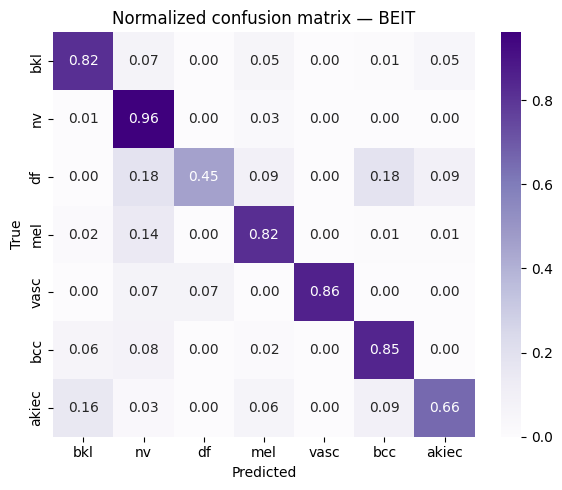

              precision    recall  f1-score   support

         bkl       0.87      0.82      0.84       110
          nv       0.95      0.96      0.96       671
          df       0.62      0.45      0.53        11
         mel       0.76      0.82      0.79       112
        vasc       1.00      0.86      0.92        14
         bcc       0.85      0.85      0.85        52
       akiec       0.75      0.66      0.70        32

    accuracy                           0.91      1002
   macro avg       0.83      0.77      0.80      1002
weighted avg       0.91      0.91      0.91      1002



In [ ]:
# ============================================================
# CELL 9 — Evaluate any saved model
# ============================================================
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class_names = list(label_map.keys())

def evaluate_saved_model(model_key):
    save_path  = os.path.join(save_dir, f"{model_key}_best.pth")
    checkpoint = torch.load(save_path, map_location=device)

    processor = AutoImageProcessor.from_pretrained(
        checkpoint["hf_name"], use_fast=True
    )
    model = AutoModelForImageClassification.from_pretrained(
        checkpoint["hf_name"], num_labels=7, ignore_mismatched_sizes=True, use_safetensors=True
    )
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device).eval()

    test_ds     = HAM10000(test_df, processor, is_train=False)
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False,
                             num_workers=0, pin_memory=True)

    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in tqdm(test_loader, desc=f"Evaluating {model_key}"):
            pv  = batch["pixel_values"].to(device)
            lbl = batch["labels"].to(device)
            all_preds.extend(
                model(pixel_values=pv).logits.argmax(-1).cpu().numpy()
            )
            all_labels.extend(lbl.cpu().numpy())

    cm      = confusion_matrix(all_labels, all_preds)
    cm_norm = cm.astype("float") / (cm.sum(axis=1, keepdims=True) + 1e-8)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Purples",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Normalized confusion matrix — {model_key.upper()}")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout(); plt.show()

    print(classification_report(all_labels, all_preds,
                                target_names=class_names))

    del model, test_ds, test_loader
    gc.collect()
    torch.cuda.empty_cache()

#evaluate_saved_model("vit")
#evaluate_saved_model("swin")
#evaluate_saved_model("deit")
evaluate_saved_model("beit")

In [ ]:
# ============================================================
# FINAL DATA DISTRIBUTION SUMMARY
# ============================================================
def display_dataset_stats(train, val, test):
    total = len(train) + len(val) + len(test)

    print("="*50)
    print(f"{'Data Split':<15} | {'Images':<10} | {'Ratio (%)':<10}")
    print("-" * 50)
    print(f"{'Training':<15} | {len(train):<10} | {len(train)/total:>9.1%}")
    print(f"{'Validation':<15} | {len(val):<10} | {len(val)/total:>9.1%}")
    print(f"{'Testing':<15} | {len(test):<10} | {len(test)/total:>9.1%}")
    print("-" * 50)
    print(f"{'TOTAL':<15} | {total:<10} | 100.0%")
    print("="*50)

display_dataset_stats(train_df, val_df, test_df)

Data Split      | Images     | Ratio (%) 
--------------------------------------------------
Training        | 8012       |     80.0%
Validation      | 1001       |     10.0%
Testing         | 1002       |     10.0%
--------------------------------------------------
TOTAL           | 10015      | 100.0%


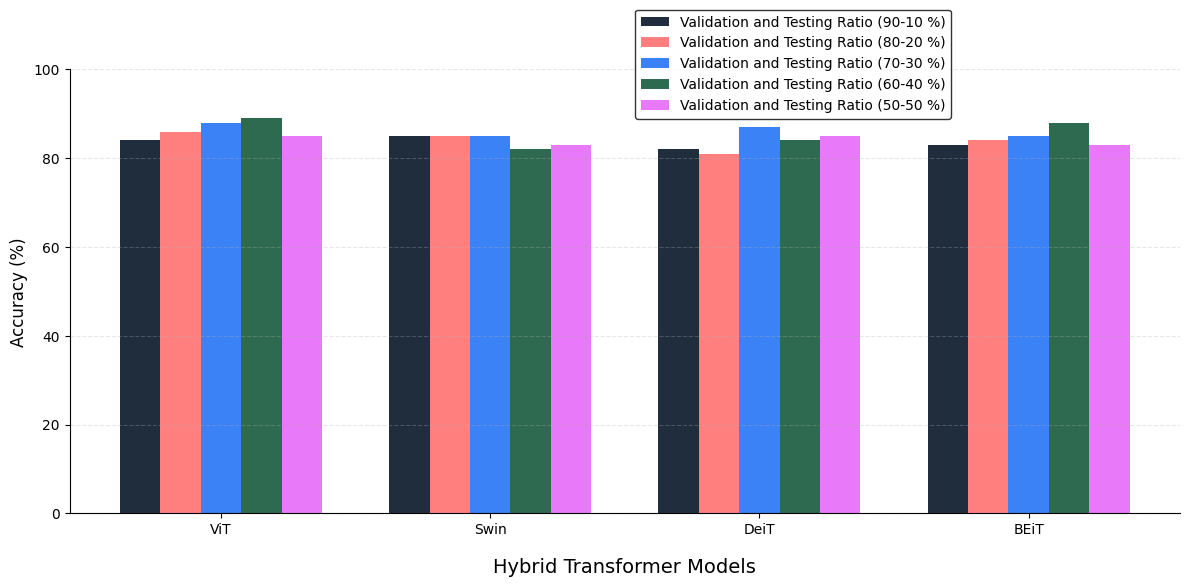

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Update these numbers with the 'Val Acc' you got from your training runs
# Format: "Model": [Ratio 90-10, Ratio 80-20, Ratio 70-30, Ratio 60-40, Ratio 50-50]
data = {
    "ViT":   [84, 86, 88, 89, 85],
    "Swin":  [85, 85, 85, 82, 83],
    "DeiT":  [82, 81, 87, 84, 85],
    "BEiT":  [83, 84, 85, 88, 83]
}

ratios = ["90-10 %", "80-20 %", "70-30 %", "60-40 %", "50-50 %"]
models = list(data.keys())
colors = ['#1f2d3d', '#ff7f7f', '#3b82f6', '#2d6a4f', '#e879f9'] # Matching your image colors

x = np.arange(len(models))
width = 0.15

fig, ax = plt.subplots(figsize=(12, 6))

# Create bars for each ratio
for i, ratio_label in enumerate(ratios):
    accuracies = [data[model][i] for model in models]
    ax.bar(x + i*width, accuracies, width, label=f"Validation and Testing Ratio ({ratio_label})", color=colors[i])

# Formatting to match reference image
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_xlabel('Hybrid Transformer Models', fontsize=14, labelpad=15)
ax.set_xticks(x + width * 2)
ax.set_xticklabels(models)
ax.set_ylim(0, 100)
ax.legend(loc='upper right', bbox_to_anchor=(0.8, 1.15), ncol=1, frameon=True, edgecolor='black')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

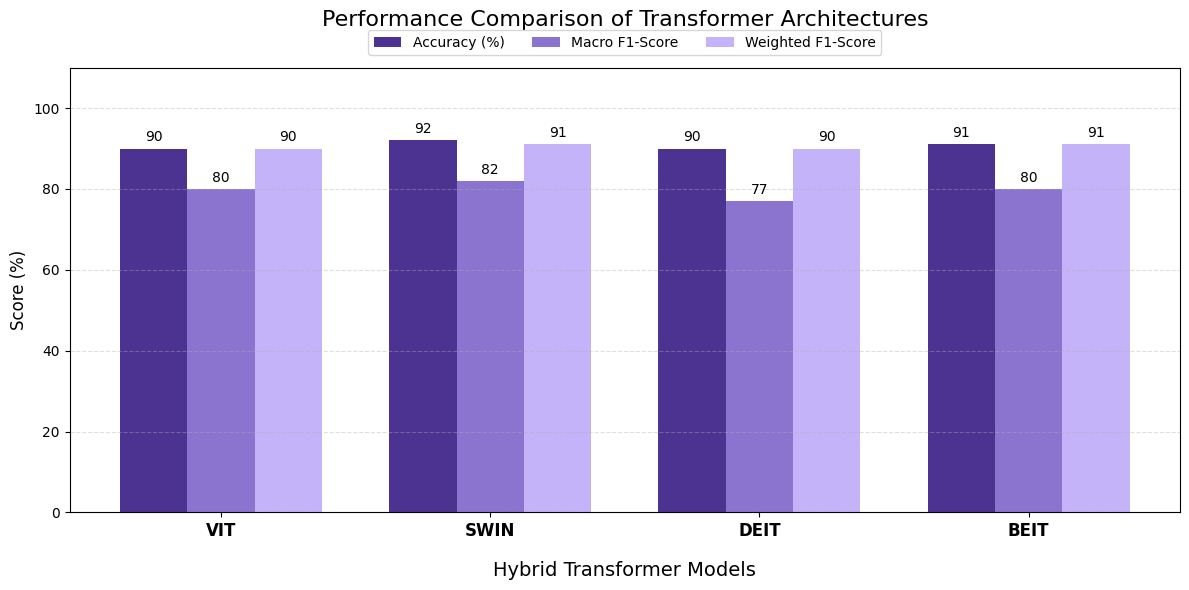

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data extracted
models = ['VIT', 'SWIN', 'DEIT', 'BEIT']
accuracy = [90, 92, 90, 91]
macro_f1 = [80, 82, 77, 80]
weighted_f1 = [90, 91, 90, 91]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

# Plotting the bars
rects1 = ax.bar(x - width, accuracy, width, label='Accuracy (%)', color='#4c3391')
rects2 = ax.bar(x, macro_f1, width, label='Macro F1-Score', color='#8a74cf')
rects3 = ax.bar(x + width, weighted_f1, width, label='Weighted F1-Score', color='#c5b3f9')

# Adding labels and styling
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=12, fontweight='bold')
ax.set_ylim(0, 110) # Extra space for legend
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.1), ncol=3, frameon=True)

# Add value labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.xlabel("Hybrid Transformer Models", fontsize=14, labelpad=15)
plt.title("Performance Comparison of Transformer Architectures", fontsize=16, pad=30)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

# Save for report
plt.savefig("model_performance_comparison.png", dpi=300)
plt.show()

In [ ]:
pip install opencv-python

In [ ]:
import os
import cv2
import torch
import numpy as np
from PIL import Image
from tqdm import tqdm
import gc

# 1. SETUP
n_images = 100
output_dir = os.path.join(save_dir, "Final_Thesis_Gallery")
os.makedirs(output_dir, exist_ok=True)

# Ensuring to use same 100 images for every model comparison
sample_df = test_df.sample(n=min(n_images, len(test_df)), random_state=42)

# 2. AUTOMATED LOOP
for model_key in MODEL_CONFIG.keys():
    print(f"\n{'='*40}")
    print(f" AUTOMATED PROCESSING: {model_key.upper()}")
    print(f"{'='*40}")

    # Path to your saved .pth file
    save_path = os.path.join(save_dir, f"{model_key}_best.pth")
    if not os.path.exists(save_path):
        print(f"Skipping {model_key}: No weights found at {save_path}")
        continue

    # Load the specific checkpoint
    checkpoint = torch.load(save_path, map_location=device)

    # Load model with ALL necessary flags for the loop to run solo
    model = AutoModelForImageClassification.from_pretrained(
        checkpoint["hf_name"],
        num_labels=7,
        use_safetensors=True,
        ignore_mismatched_sizes=True, # Fixes the 1000 vs 7 class error
        output_attentions=True        # Fixes the IndexError
    ).to(device).eval()

    model.load_state_dict(checkpoint["state_dict"])
    processor = AutoImageProcessor.from_pretrained(checkpoint["hf_name"])

    # Create model-specific subfolder
    model_folder = os.path.join(output_dir, model_key)
    os.makedirs(model_folder, exist_ok=True)

    # Internal Loop for the 100 images
    for _, row in tqdm(sample_df.iterrows(), total=len(sample_df), desc=f"Mapping {model_key}"):
        # Image Processing
        raw_img = Image.open(row['image_path']).convert("RGB")
        inputs = processor(images=raw_img, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = model(**inputs) # output_attentions is now baked into the model config

        # Architecture-specific attention extraction
        try:
            if model_key in ["vit", "deit", "beit"]:
                # Standard Transformer Rollout
                attn = outputs.attentions[-1][0]
                mask = torch.mean(attn, dim=0)[0, 1:].reshape(14, 14).cpu().numpy()
            elif model_key == "swin":
                # Swin Hierarchical Window Attention
                last_attn = outputs.attentions[-1]
                mask = torch.mean(last_attn[0], dim=0).mean(dim=0).reshape(7, 7).cpu().numpy()

            # Normalize and Colorize
            mask = cv2.resize(mask, (224, 224))
            mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
            heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)

            # Overlay on original image
            img_np = np.array(raw_img.resize((224, 224)))
            heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
            overlay = cv2.addWeighted(img_np, 0.6, heatmap_rgb, 0.4, 0)

            # Save
            cv2.imwrite(os.path.join(model_folder, f"{row['image_id']}_attn.jpg"), cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))

        except Exception as e:
            print(f"Error on image {row['image_id']}: {e}")
            continue

    # Cleanup memory before the next model in the loop starts
    del model, processor
    gc.collect()
    torch.cuda.empty_cache()

print(f"\n{'='*40}")
print(f" ALL MODELS PROCESSED SUCCESSFULLY")
print(f" Files saved in: {output_dir}")


 AUTOMATED PROCESSING: VIT


C:\Users\Admin\AppData\Local\Temp\ipykernel_28936\3425396759.py:30: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path, map_location=device)
[tr

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
Mapping vit: 100%|███████████████████████████████████████████████████████████████████| 100/100 [00:05<00:00, 19.63it/s]



 AUTOMATED PROCESSING: SWIN


...


 AUTOMATED PROCESSING: BEIT


[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[transformers] BeitForImageClassification LOAD REPORT from: microsoft/beit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
Mapping beit: 100%|██████████████████████████████████████████████████████████████████| 100/100 [00:04<00:00, 23.13it/s]



 ALL MODELS PROCESSED SUCCESSFULLY
 Files saved in: C:\Users\Admin\Google Drive\MyDrive\skin_cancer_models\Final_Thesis_Gallery


In [ ]:
# "Cheat Sheet" for gallery categories
for dx_class in label_map.keys():
    # Finding first image in sample that matches this disease
    example = sample_df[sample_df['dx'] == dx_class].head(1)
    if not example.empty:
        print(f"Class: {dx_class:<5} | Image ID: {example.iloc[0]['image_id']}")

In [ ]:
import cv2
import numpy as np
import os
import glob

# 1. Root path
base_path = r"C:\Users\Admin\Google Drive\MyDrive\skin_cancer_models\7_Classes_maps"
output_path = r"C:\Users\Admin\Google Drive\MyDrive\skin_cancer_models\7_Proposed_Fusion_Results"

if not os.path.exists(output_path):
    os.makedirs(output_path)

# 2. These lists stay the same
classes = ['mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df', 'nv']
models = ['vit', 'swin', 'deit', 'beit']

def create_joint_fusion():
    # First, let's find EVERY image file in that directory once
    print("Indexing all files... please wait.")
    all_files_in_drive = glob.glob(os.path.join(base_path, "**", "*.*"), recursive=True)
    print(f"Total files found to scan: {len(all_files_in_drive)}")

    for disease in classes:
        print(f"\n--- Processing: {disease.upper()} ---")
        all_maps = []

        for model in models:
            # File with bOTH the disease name and the model name
            match = [f for f in all_files_in_drive if disease in f.lower() and model in f.lower()]

            if match:
                target_file = match[0]
                img = cv2.imread(target_file, cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    img_res = cv2.resize(img, (224, 224))
                    all_maps.append(img_res.astype(np.float32))
                    print(f"   [OK] Found {model}: {os.path.basename(target_file)}")
                else:
                    print(f"   [Error] Could not read file: {target_file}")
            else:
                print(f"   [MISSING] No file found for {disease} + {model}")

        if len(all_maps) == 4:
            fused_array = np.mean(all_maps, axis=0)
            fused_norm = cv2.normalize(fused_array, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
            heatmap = cv2.applyColorMap(fused_norm, cv2.COLORMAP_JET)

            save_path = os.path.join(output_path, f"{disease}_Proposed_Fusion.jpg")
            cv2.imwrite(save_path, heatmap)
            print(f">>> SUCCESS: {disease}_Proposed_Fusion.jpg saved!")
        else:
            print(f"!!! FAILED: Found {len(all_maps)}/4 for {disease}")

if __name__ == "__main__":
    create_joint_fusion()

# VISION LLM Llama3.2-vision

In [ ]:
pip install torch torchvision transformers accelerate pillow

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install ollama

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# install the required LangChain integrations
!pip install langchain-ollama langchain-core

In [ ]:
import os
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage
import base64

# -------------------------------
# CONFIG
# -------------------------------
# Windows path
BASE_PATH = r"C:\Users\Admin\Google Drive\MyDrive\skin_cancer_models\7_Proposed_Fusion_Results"
MODEL_NAME = "llama3.2-vision:11b"

# -------------------------------
# MEDICAL KNOWLEDGE BASE (V-RAG)
# -------------------------------
medical_kb = {
    "mel": "Melanoma is malignant. Features: asymmetry, irregular pigment network, multiple colors, regression structures.",
    "bkl": "Benign keratosis is non-cancerous. Features: milia-like cysts, comedo-like openings, waxy texture.",
    "bcc": "Basal cell carcinoma is malignant. Features: arborizing vessels, blue-gray ovoid nests, ulceration.",
    "akiec": "Actinic keratosis is pre-malignant. Features: erythematous pseudonetwork, scaling, keratin.",
    "vasc": "Vascular lesions are benign. Features: red-blue lacunae, homogeneous red coloration.",
    "df": "Dermatofibroma is benign. Features: central white scar-like area, peripheral pigment network.",
    "nv": "Melanocytic nevus is benign. Features: symmetric structure, uniform pigment, globular patterns."
}

# Helper to encode image for the VLLM
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode('utf-8')

# Initialize the Local Ollama Model
llm = ChatOllama(model=MODEL_NAME, temperature=0.1)

# -------------------------------
# MAIN EXECUTION
# -------------------------------
print(f"--- Starting V-RAG Analysis for 7 Classes ---\n")

for code, context in medical_kb.items():
    image_path = os.path.join(BASE_PATH, f"{code}_Proposed_Fusion.jpg")

    if not os.path.exists(image_path):
        print(f"Skipping {code.upper()}: Image not found.")
        continue

    # Encode the Fused Map
    img_base64 = encode_image(image_path)

    # Build the V-RAG Prompt
    prompt = f"""[SYSTEM: CLINICAL V-RAG]
    CLASS: {code.upper()}
    KNOWLEDGE: {context}
    TASK: Use the red hotspot in the map and the knowledge above to write a 2-sentence rationale.
    Sentence 1: Describe feature in hotspot.
    Sentence 2: Link feature to diagnosis.
    Max 40 words."""

    # Create the Multimodal Message
    message = HumanMessage(
        content=[
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": f"data:image/jpeg;base64,{img_base64}"},
        ]
    )

    # Invoke the model
    try:
        response = llm.invoke([message])
        print(f"{code.upper()} RATIONALE:\n{response.content}\n")
    except Exception as e:
        print(f"Error processing {code.upper()}: {e}")

print("--- Analysis Complete ---")

--- Starting V-RAG Analysis for 7 Classes ---

MEL RATIONALE:
The red hotspot in the map indicates an irregular pigment network, which is a feature of melanoma. This feature is consistent with the knowledge that melanoma is malignant and can be identified by irregularities in skin pigmentation.

BKL RATIONALE:
The red hotspot in the map highlights a milia-like cyst, characterized by a small, rounded, and well-circumscribed lesion with a waxy texture. This feature is consistent with the diagnosis of benign keratosis, a non-cancerous condition.

BCC RATIONALE:
The red hotspot in the map indicates arborizing vessels, which are characteristic of basal cell carcinoma. This feature is a key indicator of the malignant nature of the tumor, as described in the knowledge base.

AKIEC RATIONALE:
The red hotspot in the map indicates an erythematous pseudonetwork, characterized by a network-like pattern of redness on the skin's surface. This feature is consistent with actinic keratosis, a pre-malig